In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

# ============================================================
# SETTINGS
# ============================================================

N = 2_000

HALF_SPREAD = 0.03      # quote +/- 3 cents around reservation price
INVENTORY_SKEW = 0.015  # move quote centre 1.5c per inventory unit
MAX_INVENTORY = 5

BASE_FILL_PROB = 0.08
TOXICITY = 3.0

FEE = 0.002


# ============================================================
# LATENT FAIR VALUE
# ============================================================

fair_value = np.empty(N)

fair_value[0] = 100

fair_value[1:] = (
    100
    + np.cumsum(
        rng.normal(
            0,
            0.025,
            N - 1
        )
    )
)


# ============================================================
# MARKET MAKER
# ============================================================

inventory = 0
cash = 0

rows = []


for t in range(N - 1):

    fv = fair_value[t]
    future_fv = fair_value[t + 1]

    # --------------------------------------------------------
    # INVENTORY-AWARE FAIR / RESERVATION PRICE
    #
    # long inventory  -> shift quotes DOWN
    # short inventory -> shift quotes UP
    # --------------------------------------------------------

    reservation_price = (
        fv
        - INVENTORY_SKEW * inventory
    )


    # --------------------------------------------------------
    # SET BID AND ASK
    # --------------------------------------------------------

    bid = (
        reservation_price
        - HALF_SPREAD
    )

    ask = (
        reservation_price
        + HALF_SPREAD
    )


    # --------------------------------------------------------
    # INVENTORY LIMITS
    #
    # If already very long, stop bidding.
    # If already very short, stop offering.
    # --------------------------------------------------------

    quote_bid = (
        inventory < MAX_INVENTORY
    )

    quote_ask = (
        inventory > -MAX_INVENTORY
    )


    # --------------------------------------------------------
    # TOY FILL PROCESS
    #
    # If price is about to fall:
    # sellers are more likely to hit our BID.
    #
    # If price is about to rise:
    # buyers are more likely to hit our ASK.
    #
    # This creates adverse selection.
    # --------------------------------------------------------

    future_move = (
        future_fv
        - fv
    )

    p_bid_fill = (
        BASE_FILL_PROB
        * np.exp(
            -TOXICITY
            * future_move
        )
    )

    p_ask_fill = (
        BASE_FILL_PROB
        * np.exp(
            +TOXICITY
            * future_move
        )
    )

    p_bid_fill = np.clip(
        p_bid_fill,
        0,
        0.5
    )

    p_ask_fill = np.clip(
        p_ask_fill,
        0,
        0.5
    )


    bid_fill = (
        quote_bid
        and
        rng.random() < p_bid_fill
    )

    ask_fill = (
        quote_ask
        and
        rng.random() < p_ask_fill
    )


    # Only allow one fill per step
    # for simplicity

    if bid_fill and ask_fill:

        if rng.random() < 0.5:
            ask_fill = False

        else:
            bid_fill = False


    event = "NONE"
    fill_price = np.nan


    # --------------------------------------------------------
    # BID FILLED
    #
    # Someone sells to us.
    # We BUY.
    # Inventory increases.
    # --------------------------------------------------------

    if bid_fill:

        inventory += 1

        cash -= (
            bid
            + FEE
        )

        event = "BUY @ BID"

        fill_price = bid


    # --------------------------------------------------------
    # ASK FILLED
    #
    # Someone buys from us.
    # We SELL.
    # Inventory decreases.
    # --------------------------------------------------------

    elif ask_fill:

        inventory -= 1

        cash += (
            ask
            - FEE
        )

        event = "SELL @ ASK"

        fill_price = ask


    # --------------------------------------------------------
    # MARK INVENTORY TO FAIR VALUE
    # --------------------------------------------------------

    wealth = (
        cash
        + inventory * future_fv
    )


    rows.append({

        "t":
            t,

        "fair_value":
            fv,

        "reservation_price":
            reservation_price,

        "bid":
            bid,

        "ask":
            ask,

        "event":
            event,

        "fill_price":
            fill_price,

        "inventory":
            inventory,

        "future_fv":
            future_fv,

        "cash":
            cash,

        "wealth":
            wealth,

    })


df = pd.DataFrame(rows)

df.head(20)

,t,fair_value,reservation_price,bid,ask,event,fill_price,inventory,future_fv,cash,wealth
0,0,100.000000,100.000000,99.970000,100.030000,NONE,NaN,0,100.000031,0.000000,0.000000
1,1,100.000031,100.000031,99.970031,100.030031,SELL @ ASK,100.030031,-1,100.007499,100.028031,0.020531
2,2,100.007499,100.022499,99.992499,100.052499,NONE,NaN,-1,100.000646,100.028031,0.027385
3,3,100.000646,100.015646,99.985646,100.045646,NONE,NaN,-1,99.978381,100.028031,0.049650
4,4,99.978381,99.993381,99.963381,100.023381,NONE,NaN,-1,99.967014,100.028031,0.061016
5,5,99.967014,99.982014,99.952014,100.012014,NONE,NaN,-1,99.942223,100.028031,0.085808
6,6,99.942223,99.957223,99.927223,99.987223,BUY @ BID,99.927223,0,99.943727,0.098808,0.098808
7,7,99.943727,99.943727,99.913727,99.973727,SELL @ ASK,99.973727,-1,99.977232,100.070534,0.093302
8,8,99.977232,99.992232,99.962232,100.022232,BUY @ BID,99.962232,0,99.964927,0.106302,0.106302
9,9,99.964927,99.964927,99.934927,99.994927,NONE,NaN,0,99.949415,0.106302,0.106302


In [11]:
fills = df[
    df["event"] != "NONE"
].copy()

fills[
    [
        "t",
        "fair_value",
        "bid",
        "ask",
        "event",
        "fill_price",
        "inventory",
        "future_fv",
        "wealth",
    ]
].head(30)

,t,fair_value,bid,ask,event,fill_price,inventory,future_fv,wealth
1,1,100.000031,99.970031,100.030031,SELL @ ASK,100.030031,-1,100.007499,0.020531
6,6,99.942223,99.927223,99.987223,BUY @ BID,99.927223,0,99.943727,0.098808
7,7,99.943727,99.913727,99.973727,SELL @ ASK,99.973727,-1,99.977232,0.093302
8,8,99.977232,99.962232,100.022232,BUY @ BID,99.962232,0,99.964927,0.106302
23,23,99.758187,99.728187,99.788187,SELL @ ASK,99.788187,-1,99.764968,0.127521
29,29,99.686615,99.671615,99.731615,SELL @ ASK,99.731615,-2,99.689448,0.243208
31,31,99.651194,99.651194,99.711194,BUY @ BID,99.651194,-1,99.639251,0.329659
36,36,99.600901,99.585901,99.645901,SELL @ ASK,99.645901,-2,99.600088,0.412635
43,43,99.578545,99.578545,99.638545,SELL @ ASK,99.638545,-3,99.580448,0.508011
84,84,99.634688,99.649688,99.709688,SELL @ ASK,99.709688,-4,99.629756,0.438020


In [12]:
first_buy = fills[
    fills["event"] == "BUY @ BID"
].index[0]

df.loc[
    first_buy:first_buy + 10,
    [
        "t",
        "fair_value",
        "reservation_price",
        "bid",
        "ask",
        "event",
        "inventory",
    ]
]

,t,fair_value,reservation_price,bid,ask,event,inventory
6,6,99.942223,99.957223,99.927223,99.987223,BUY @ BID,0
7,7,99.943727,99.943727,99.913727,99.973727,SELL @ ASK,-1
8,8,99.977232,99.992232,99.962232,100.022232,BUY @ BID,0
9,9,99.964927,99.964927,99.934927,99.994927,NONE,0
10,10,99.949415,99.949415,99.919415,99.979415,NONE,0
11,11,99.961661,99.961661,99.931661,99.991661,NONE,0
12,12,99.970583,99.970583,99.940583,100.000583,NONE,0
13,13,99.973219,99.973219,99.943219,100.003219,NONE,0
14,14,99.949957,99.949957,99.919957,99.979957,NONE,0
15,15,99.949226,99.949226,99.919226,99.979226,NONE,0


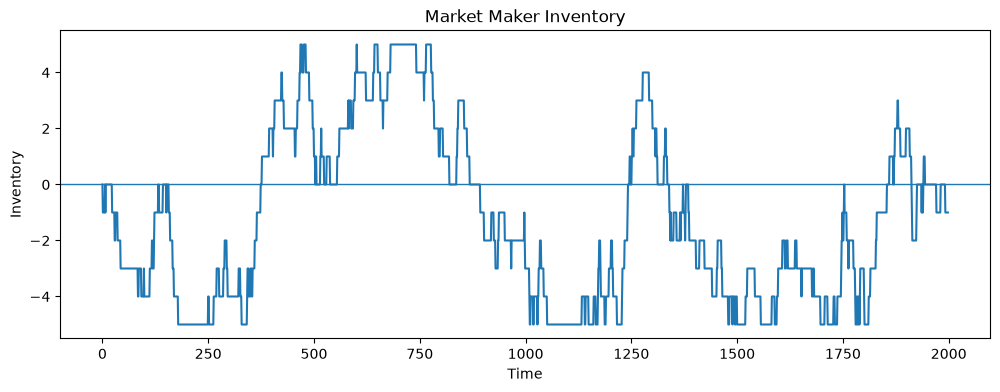

In [13]:
plt.figure(figsize=(12, 4))

plt.plot(
    df["t"],
    df["inventory"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Time")
plt.ylabel("Inventory")

plt.title(
    "Market Maker Inventory"
)

plt.show()

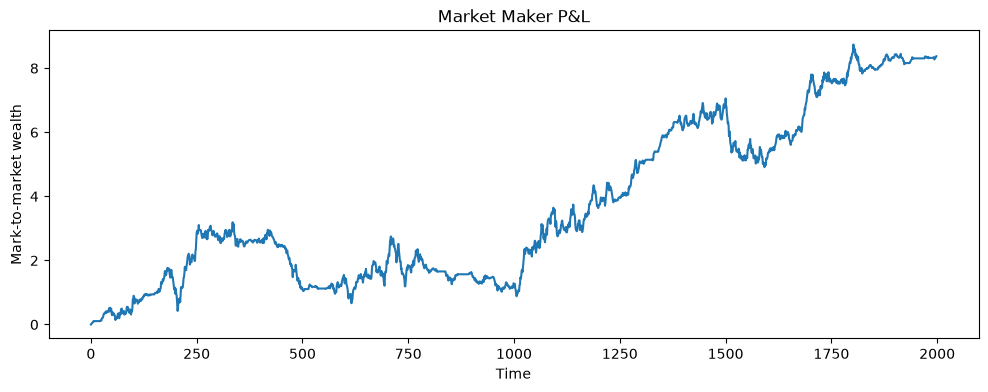

In [14]:
plt.figure(figsize=(12, 4))

plt.plot(
    df["t"],
    df["wealth"]
)

plt.xlabel("Time")

plt.ylabel(
    "Mark-to-market wealth"
)

plt.title(
    "Market Maker P&L"
)

plt.show()

In [15]:
fills = df[
    df["event"] != "NONE"
].copy()


fills["markout"] = np.where(

    fills["event"] == "BUY @ BID",

    # Buy:
    # want future FV ABOVE our purchase price
    fills["future_fv"]
    - fills["fill_price"],

    # Sell:
    # want future FV BELOW our sale price
    fills["fill_price"]
    - fills["future_fv"]

)


fills[
    [
        "event",
        "fill_price",
        "fair_value",
        "future_fv",
        "markout",
    ]
].head(20)

,event,fill_price,fair_value,future_fv,markout
1,SELL @ ASK,100.030031,100.000031,100.007499,0.022531
6,BUY @ BID,99.927223,99.942223,99.943727,0.016504
7,SELL @ ASK,99.973727,99.943727,99.977232,-0.003505
8,BUY @ BID,99.962232,99.977232,99.964927,0.002695
23,SELL @ ASK,99.788187,99.758187,99.764968,0.023218
29,SELL @ ASK,99.731615,99.686615,99.689448,0.042167
31,BUY @ BID,99.651194,99.651194,99.639251,-0.011944
36,SELL @ ASK,99.645901,99.600901,99.600088,0.045813
43,SELL @ ASK,99.638545,99.578545,99.580448,0.058096
84,SELL @ ASK,99.709688,99.634688,99.629756,0.079932


In [16]:
print(
    "Average markout:",
    fills["markout"].mean()
)

print(
    "Negative markout rate:",
    (
        fills["markout"] < 0
    ).mean()
)

print(
    "Number of fills:",
    len(fills)
)

Average markout: 0.020501739945609544
Negative markout rate: 0.3824561403508772
Number of fills: 285


## Market Making: The Core Mental Model

A market maker is **not** guaranteed to buy at the bid and then sell at the ask.

Instead:

$$
\boxed{
\text{Accept temporary inventory}
\rightarrow
\text{manage it}
\rightarrow
\text{try to earn the spread}
}
$$

The basic economics are:

$$
\boxed{
\text{Spread capture}
>
\text{adverse selection}
+
\text{inventory losses}
+
\text{fees}
+
\text{hedging costs}
}
$$

---

## What Happens After One Side Fills?

Suppose:

$$
F_t = 100.00
$$

and the market maker quotes:

$$
99.97 / 100.03
$$

If the bid is hit, the market maker buys at:

$$
99.97
$$

and becomes long.

It is now exposed to market risk until it either:

- gets filled on the ask,
- reprices the ask,
- hedges elsewhere,
- or crosses the spread to reduce inventory.

So your intuition is correct: **market making does involve market risk between fills**.

---

## Inventory Skew

The market maker does not usually leave the same quotes unchanged after a fill.

A simple inventory-adjusted reservation price is:

$$
r_t = F_t - \lambda q_t
$$

where:

- $F_t$ = fair value
- $q_t$ = inventory
- $\lambda$ = inventory-risk parameter

If:

$$
F_t = 100
$$

$$
q_t = +1
$$

$$
\lambda = 0.015
$$

then:

$$
r_t = 99.985
$$

Instead of quoting:

$$
99.97 / 100.03
$$

the market maker might now quote:

$$
99.955 / 100.015
$$

This does two things:

- lowers the bid, reducing the chance of buying more;
- lowers the ask, increasing the chance of selling the existing long inventory.

---

## Spread Capture Is the Reward for Risk

Good case:

$$
\text{Buy}=99.97
$$

$$
\text{Sell}=100.03
$$

so:

$$
\text{Gross capture}=0.06
$$

But suppose fair value falls after the buy and the market maker is forced to sell at:

$$
99.79
$$

Then:

$$
99.79 - 99.97 = -0.18
$$

So one bad inventory event can wipe out several successful spread captures.

---

## Adverse Selection

Fills are not random.

For a passive buy, define the markout as:

$$
M_h = F_{t+h} - P_{\text{fill}}
$$

If:

$$
P_{\text{fill}} = 99.97
$$

and shortly afterwards:

$$
F_{t+h} = 99.90
$$

then:

$$
M_h = -0.07
$$

That means the market moved against you after the fill.

This is why a market maker cares about both:

$$
P(\text{fill})
$$

and:

$$
E[M_h \mid \text{fill}]
$$

More fills are not necessarily better if those fills have worse markouts.

---

## Where Fair Value Fits

Fair value determines where the market maker wants to centre its quotes.

If the public mid is:

$$
100.00
$$

but your model estimates:

$$
F_t = 100.05
$$

then quoting around $100.00$ may leave your ask too cheap.

A better fair value helps you avoid stale or toxic quotes.

So for market making, a better FV often means:

$$
\boxed{
\text{fewer adverse fills}
}
$$

rather than simply more fills.

---

## If Inventory Gets Too Large

As inventory risk increases, the market maker can become progressively more aggressive:

$$
\text{skew quotes}
\rightarrow
\text{reduce size}
\rightarrow
\text{stop quoting one side}
\rightarrow
\text{hedge elsewhere}
\rightarrow
\text{cross the spread}
$$

For example, if you become long BTC on Hyperliquid, you might immediately sell BTC on Binance to neutralise the exposure.

---

## Final Mental Model

Market making is approximately:

$$
\boxed{
\text{earn many small spread captures}
}
$$

while trying to prevent:

$$
\boxed{
\text{inventory risk + adverse selection}
}
$$

from overwhelming those gains.

The goal is not to eliminate market risk. It is to make that risk **small, short-lived, measurable, and actively controlled**.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# MARKET MAKER SIMULATION
# ============================================================

def run_market_maker(
    refresh_ms,
    seed=1,
    step_ms=50,
    n_steps=8_000,
    half_spread=0.04,
    inventory_skew=0.012,
    base_fill_prob=0.05,
    max_inventory=5,
):

    rng = np.random.default_rng(seed)

    # --------------------------------------------------------
    # LATENT FAIR VALUE
    # One observation every 50 ms
    # --------------------------------------------------------

    fv = np.empty(n_steps)

    fv[0] = 100

    fv[1:] = (
        100
        + np.cumsum(
            rng.normal(
                0,
                0.012,
                n_steps - 1
            )
        )
    )


    refresh_steps = max(
        1,
        round(refresh_ms / step_ms)
    )


    inventory = 0
    cash = 0

    bid = np.nan
    ask = np.nan

    rows = []
    fills = []


    # ========================================================
    # MAIN LOOP
    # ========================================================

    for t in range(n_steps - 1):


        # ----------------------------------------------------
        # ONLY UPDATE QUOTES AT THE REFRESH INTERVAL
        #
        # 50ms strategy:
        # refresh every observation
        #
        # 500ms strategy:
        # quote may remain unchanged for 10 observations
        # ----------------------------------------------------

        if t % refresh_steps == 0:

            reservation_price = (
                fv[t]
                - inventory_skew * inventory
            )

            bid = (
                reservation_price
                - half_spread
            )

            ask = (
                reservation_price
                + half_spread
            )


        # ----------------------------------------------------
        # FILL PROBABILITY
        #
        # If our bid becomes high relative to current FV,
        # sellers become increasingly willing to hit it.
        #
        # If our ask becomes low relative to current FV,
        # buyers become increasingly willing to lift it.
        #
        # This creates stale-quote adverse selection.
        # ----------------------------------------------------

        p_bid_fill = (
            base_fill_prob
            * np.exp(
                np.clip(
                    (bid - fv[t]) / 0.02,
                    -3,
                    2
                )
            )
        )

        p_ask_fill = (
            base_fill_prob
            * np.exp(
                np.clip(
                    (fv[t] - ask) / 0.02,
                    -3,
                    2
                )
            )
        )


        p_bid_fill = min(
            float(p_bid_fill),
            0.40
        )

        p_ask_fill = min(
            float(p_ask_fill),
            0.40
        )


        bid_fill = (
            inventory < max_inventory
            and rng.random() < p_bid_fill
        )

        ask_fill = (
            inventory > -max_inventory
            and rng.random() < p_ask_fill
        )


        # Only one fill per step for simplicity

        if bid_fill and ask_fill:

            if rng.random() < 0.5:
                ask_fill = False

            else:
                bid_fill = False


        event = "NONE"
        fill_price = np.nan


        # ----------------------------------------------------
        # BID FILLED -> WE BECOME LONGER
        # ----------------------------------------------------

        if bid_fill:

            inventory += 1

            cash -= bid

            event = "BUY"

            fill_price = bid


        # ----------------------------------------------------
        # ASK FILLED -> WE BECOME SHORTER
        # ----------------------------------------------------

        elif ask_fill:

            inventory -= 1

            cash += ask

            event = "SELL"

            fill_price = ask


        if event != "NONE":

            fills.append({
                "t": t,
                "event": event,
                "fill_price": fill_price,
            })


        wealth = (
            cash
            + inventory * fv[t]
        )


        rows.append({

            "t": t,

            "time_ms":
                t * step_ms,

            "fv":
                fv[t],

            "bid":
                bid,

            "ask":
                ask,

            "inventory":
                inventory,

            "wealth":
                wealth,

        })


    history = pd.DataFrame(rows)

    fills = pd.DataFrame(fills)


    # ========================================================
    # MARKOUTS
    # ========================================================

    horizons = [
        50,
        100,
        250,
        500,
        750,
        1000,
    ]


    for horizon_ms in horizons:

        horizon_steps = round(
            horizon_ms / step_ms
        )

        markouts = []


        for _, fill in fills.iterrows():

            future_index = min(
                int(fill["t"]) + horizon_steps,
                n_steps - 1
            )

            future_fv = fv[future_index]


            # Positive markout = good
            if fill["event"] == "BUY":

                markout = (
                    future_fv
                    - fill["fill_price"]
                )

            else:

                markout = (
                    fill["fill_price"]
                    - future_fv
                )


            markouts.append(markout)


        fills[
            f"markout_{horizon_ms}ms"
        ] = markouts


    return history, fills

In [18]:
# ============================================================
# COMPARE REFRESH SPEEDS
# ============================================================

refresh_intervals = [
    50,
    250,
    500,
    750,
]


results = []


for refresh_ms in refresh_intervals:

    history, fills = run_market_maker(
        refresh_ms=refresh_ms
    )


    result = {

        "refresh_ms":
            refresh_ms,

        "fills":
            len(fills),

        "avg_abs_inventory":
            history["inventory"]
            .abs()
            .mean(),

        "max_abs_inventory":
            history["inventory"]
            .abs()
            .max(),

        "final_wealth":
            history["wealth"]
            .iloc[-1],

    }


    for horizon in [
        50,
        100,
        250,
        500,
        750,
        1000,
    ]:

        result[
            f"markout_{horizon}ms"
        ] = (
            fills[
                f"markout_{horizon}ms"
            ]
            .mean()
        )


    results.append(result)


comparison = pd.DataFrame(results)

comparison

,refresh_ms,fills,avg_abs_inventory,max_abs_inventory,final_wealth,markout_50ms,markout_100ms,markout_250ms,markout_500ms,markout_750ms,markout_1000ms
0,50,119,0.620953,3,3.168284,0.034480,0.035292,0.034027,0.033259,0.033950,0.030646
1,250,191,0.573822,3,4.756192,0.014311,0.014730,0.014836,0.013450,0.009332,0.014449
2,500,334,0.895737,4,0.744909,-0.001979,-0.002860,-0.003372,-0.002195,-0.003456,-0.000055
3,750,458,1.105513,5,-6.441078,-0.016188,-0.015947,-0.015768,-0.016554,-0.013733,-0.012153


In [19]:
# ============================================================
# COMPARE REFRESH SPEEDS
# ============================================================

refresh_intervals = [
    50,
    250,
    500,
    750,
]


results = []


for refresh_ms in refresh_intervals:

    history, fills = run_market_maker(
        refresh_ms=refresh_ms
    )


    result = {

        "refresh_ms":
            refresh_ms,

        "fills":
            len(fills),

        "avg_abs_inventory":
            history["inventory"]
            .abs()
            .mean(),

        "max_abs_inventory":
            history["inventory"]
            .abs()
            .max(),

        "final_wealth":
            history["wealth"]
            .iloc[-1],

    }


    for horizon in [
        50,
        100,
        250,
        500,
        750,
        1000,
    ]:

        result[
            f"markout_{horizon}ms"
        ] = (
            fills[
                f"markout_{horizon}ms"
            ]
            .mean()
        )


    results.append(result)


comparison = pd.DataFrame(results)

comparison

,refresh_ms,fills,avg_abs_inventory,max_abs_inventory,final_wealth,markout_50ms,markout_100ms,markout_250ms,markout_500ms,markout_750ms,markout_1000ms
0,50,119,0.620953,3,3.168284,0.034480,0.035292,0.034027,0.033259,0.033950,0.030646
1,250,191,0.573822,3,4.756192,0.014311,0.014730,0.014836,0.013450,0.009332,0.014449
2,500,334,0.895737,4,0.744909,-0.001979,-0.002860,-0.003372,-0.002195,-0.003456,-0.000055
3,750,458,1.105513,5,-6.441078,-0.016188,-0.015947,-0.015768,-0.016554,-0.013733,-0.012153


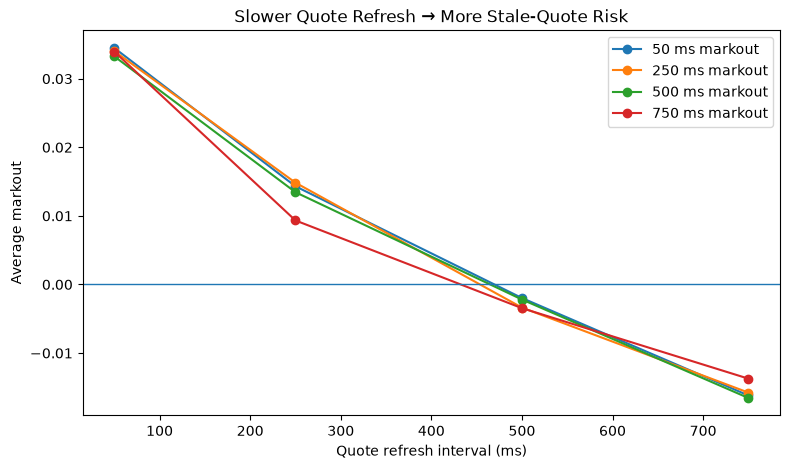

In [20]:
# ============================================================
# MARKOUT VS QUOTE REFRESH SPEED
# ============================================================

plt.figure(figsize=(9, 5))

for horizon in [
    50,
    250,
    500,
    750,
]:

    plt.plot(
        comparison["refresh_ms"],
        comparison[f"markout_{horizon}ms"],
        marker="o",
        label=f"{horizon} ms markout"
    )


plt.axhline(
    0,
    linewidth=1
)

plt.xlabel(
    "Quote refresh interval (ms)"
)

plt.ylabel(
    "Average markout"
)

plt.title(
    "Slower Quote Refresh → More Stale-Quote Risk"
)

plt.legend()

plt.show()

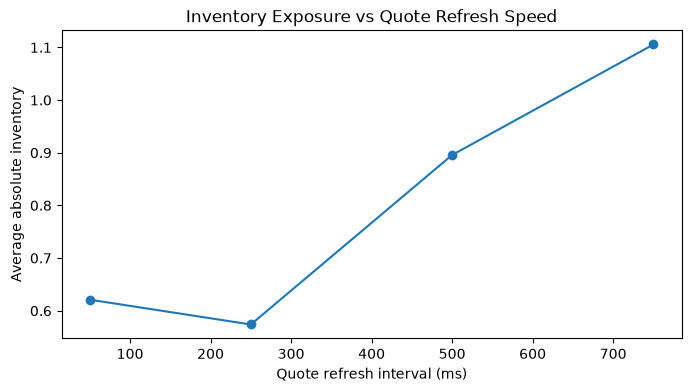

In [21]:
plt.figure(figsize=(8, 4))

plt.plot(
    comparison["refresh_ms"],
    comparison["avg_abs_inventory"],
    marker="o"
)

plt.xlabel(
    "Quote refresh interval (ms)"
)

plt.ylabel(
    "Average absolute inventory"
)

plt.title(
    "Inventory Exposure vs Quote Refresh Speed"
)

plt.show()

## Market Making at 50–750 ms: Same Economics, Different Weights

The basic P&L decomposition does **not** change with the strategy horizon:

$$
\text{Net P\&L}
\approx
\text{spread / entry edge}
-
\text{adverse selection}
-
\text{fees}
+
\text{rebates}
-
\text{hedge cost}
-
\text{inventory cost}.
$$

What changes is the **relative importance of each term**.

A useful way to think about the horizon is:

| Component | ~50 ms | ~250–500 ms | ~500–750 ms |
|---|---|---|---|
| Queue / latency advantage | High | Medium | Lower |
| Stale-quote risk | High | High | Very important |
| Fair-value quality | Important | Very important | Very important |
| Adverse-selection prediction | Important | Very important | Very important |
| Inventory management | Lower if hedged quickly | Important | More important |
| Hedge timing / slippage | Important | Important | More important |
| Fees / rebates | Important | Important | Important |

The accounting identity is therefore the same; the **control problem changes**.

---

### Forecast Horizon vs Reaction Time

A "500 ms market-making strategy" should not necessarily mean:

$$
\text{leave quote unchanged for 500 ms}.
$$

A better architecture is:

$$
\boxed{
\text{500 ms fair-value / alpha horizon}
+
\text{50–100 ms quote and risk monitoring}
}
$$

The FV model might ask:

> Where should efficient value be over the next 500 ms?

while the execution layer continually asks:

> Is my current quote still safe?

For example, a quote can be cancelled after 50 ms if:

- another venue moves;
- order flow suddenly becomes one-sided;
- volatility jumps;
- inventory becomes too large;
- the estimated fair value moves.

So the **forecast may be medium-frequency while risk management remains faster**.

---

## Why Slower Updating Can Produce More Fills

Suppose:

$$
F_t = 100.00
$$

and we quote:

$$
99.97 / 100.03.
$$

If fair value falls to:

$$
F_{t+300ms}=99.92
$$

but our bid is still sitting at:

$$
99.97,
$$

the bid has become approximately 5 cents too expensive.

That quote is now attractive to sellers, so our fill probability may actually **increase**.

But the fill is bad:

$$
\text{markout}
=
99.92-99.97
=
-0.05.
$$

This creates an important market-making pattern:

$$
\boxed{
\text{more fills}
\not\Rightarrow
\text{better strategy}
}
$$

because stale quotes can generate many fills precisely when the market has moved against us.

---

## Inventory Becomes More Important With Time

After a passive buy, inventory is:

$$
q_t > 0.
$$

Until that inventory is sold or hedged, P&L contains directional exposure:

$$
\Delta \text{P\&L}_{inventory}
\approx
q_t \Delta F_t.
$$

If:

$$
q_t=5
$$

and fair value falls by:

$$
0.10,
$$

then approximately:

$$
\Delta \text{P\&L}
=
5(-0.10)
=
-0.50.
$$

The longer inventory remains open, the more opportunity there is for price movement to dominate the spread that was originally earned.

This is why inventory-aware quoting becomes important:

$$
r_t
=
F_t-\lambda q_t.
$$

When long inventory increases, the reservation price is shifted downward so that:

- the bid becomes less aggressive;
- the ask becomes more aggressive;
- the strategy is encouraged back toward zero inventory.

---

## The Main Trade-Off

At these horizons the market maker is continually balancing:

$$
\boxed{\text{spread capture}}
$$

against:

$$
\boxed{
\text{adverse selection}
+
\text{inventory exposure}
+
\text{hedging cost}
}.
$$

A faster strategy may avoid more stale quotes but compete harder on latency and queue position.

A slower strategy may rely more heavily on:

- better fair value;
- order-flow prediction;
- identifying toxic market states;
- inventory skew;
- cross-venue hedging;
- selectively deciding when **not** to quote.

So moving from 50 ms toward 500–750 ms does not fundamentally change what market making is.

It changes **where the edge has to come from**.

---

## Literature Connection

This interpretation follows the standard market-making literature:

- **Ho & Stoll (1981)** — dealer quotes depend on inventory, asset-price risk and transaction-arrival uncertainty.
- **Avellaneda & Stoikov (2008)** — introduces the reservation-price view, where inventory shifts the centre of optimal quotes and quote distance trades off spread against fill intensity.
- **Guéant, Lehalle & Fernandez-Tapia (2011)** — develops the inventory-risk control problem further under explicit inventory constraints.
- **Cartea, Jaimungal & Ricci (2014)** — incorporates order-flow and limit-order-book information into high-frequency trading decisions.
- **Optiver practitioner material** — describes market making as continuously updating theoretical prices and quotes while being compensated for the risk of providing liquidity.

In [22]:
# ============================================================
# EQUITY + INVENTORY PATH FOR EACH REFRESH SPEED
# ============================================================

refresh_intervals = [
    50,
    250,
    500,
    750,
]

simulation_results = {}


for refresh_ms in refresh_intervals:

    history, fills = run_market_maker(
        refresh_ms=refresh_ms,
        seed=1,              # same underlying simulation seed
    )

    history = history.copy()

    # Put wealth on a P&L-like scale starting from zero.
    history["equity"] = (
        history["wealth"]
        - history["wealth"].iloc[0]
    )

    simulation_results[
        refresh_ms
    ] = {
        "history": history,
        "fills": fills,
    }

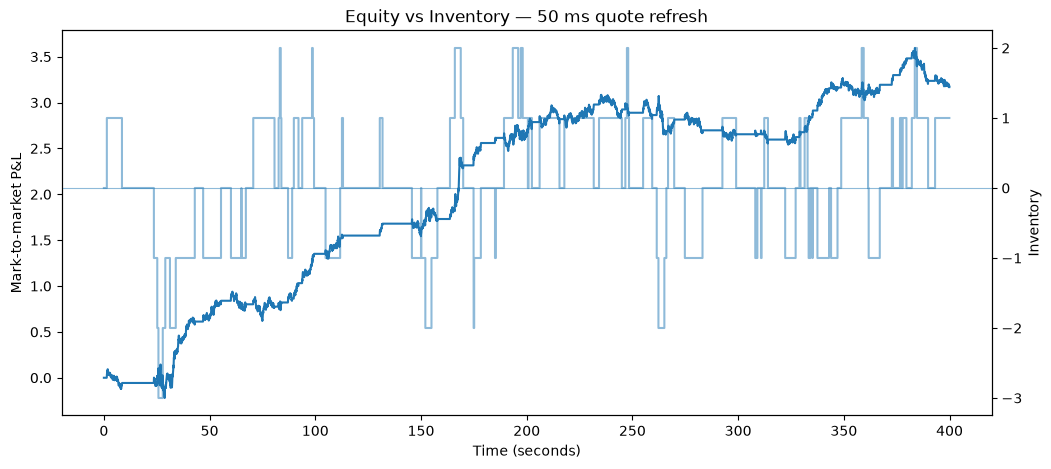

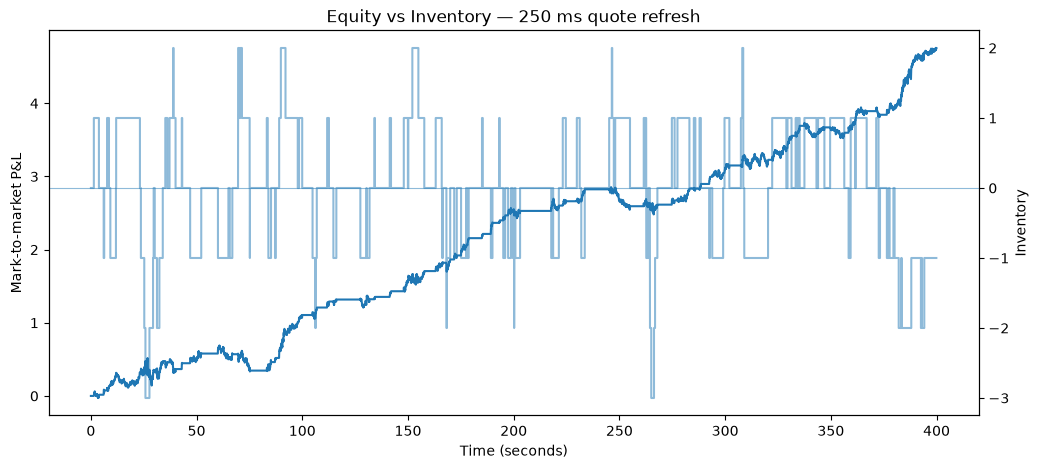

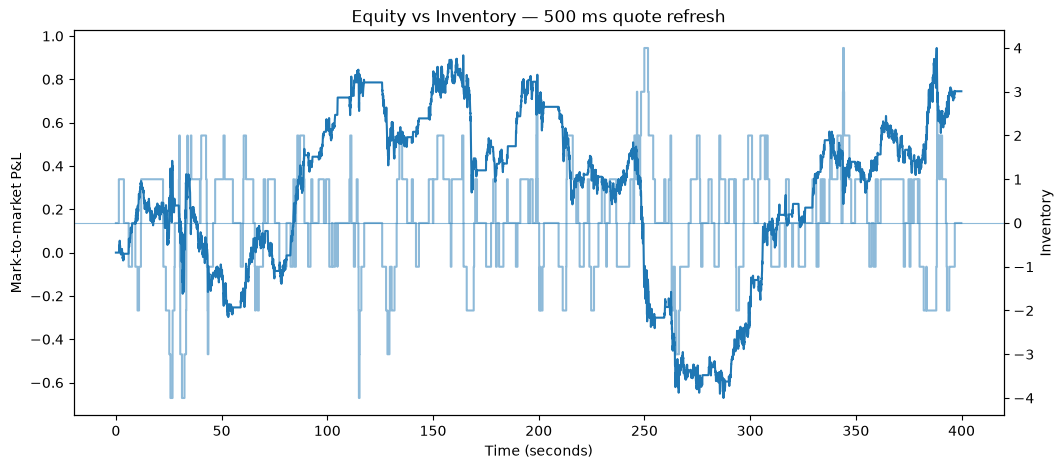

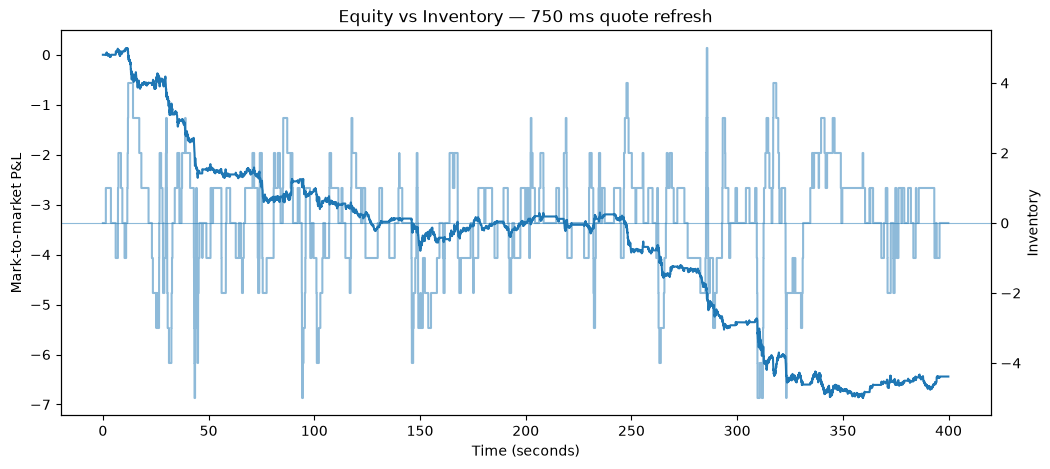

In [23]:
# ============================================================
# EQUITY VS INVENTORY
# ============================================================

for refresh_ms in refresh_intervals:

    history = simulation_results[
        refresh_ms
    ]["history"]

    time_seconds = (
        history["time_ms"]
        / 1000
    )


    fig, ax_equity = plt.subplots(
        figsize=(12, 5)
    )


    # ----------------------------
    # EQUITY
    # ----------------------------

    ax_equity.plot(
        time_seconds,
        history["equity"],
        linewidth=1.5,
        label="Equity"
    )

    ax_equity.set_xlabel(
        "Time (seconds)"
    )

    ax_equity.set_ylabel(
        "Mark-to-market P&L"
    )


    # ----------------------------
    # INVENTORY
    # ----------------------------

    ax_inventory = (
        ax_equity.twinx()
    )

    ax_inventory.step(
        time_seconds,
        history["inventory"],
        where="post",
        alpha=0.5,
        label="Inventory"
    )

    ax_inventory.set_ylabel(
        "Inventory"
    )


    # ----------------------------
    # ZERO INVENTORY LINE
    # ----------------------------

    ax_inventory.axhline(
        0,
        linewidth=0.8,
        alpha=0.5
    )


    plt.title(
        f"Equity vs Inventory — "
        f"{refresh_ms} ms quote refresh"
    )

    plt.show()

In [24]:
# ============================================================
# SUMMARY BY REFRESH SPEED
# ============================================================

summary_rows = []


for refresh_ms in refresh_intervals:

    history = simulation_results[
        refresh_ms
    ]["history"]

    fills = simulation_results[
        refresh_ms
    ]["fills"]


    summary_rows.append({

        "refresh_ms":
            refresh_ms,

        "fills":
            len(fills),

        "final_pnl":
            history["equity"].iloc[-1],

        "avg_abs_inventory":
            history["inventory"]
            .abs()
            .mean(),

        "max_abs_inventory":
            history["inventory"]
            .abs()
            .max(),

        "time_at_inventory_limit_%":
            100 * (
                history["inventory"]
                .abs()
                >= MAX_INVENTORY
            ).mean(),

        "avg_500ms_markout":
            fills["markout_500ms"].mean(),

        "avg_750ms_markout":
            fills["markout_750ms"].mean(),
    })


summary = pd.DataFrame(
    summary_rows
)

summary

,refresh_ms,fills,final_pnl,avg_abs_inventory,max_abs_inventory,time_at_inventory_limit_%,avg_500ms_markout,avg_750ms_markout
0,50,119,3.168284,0.620953,3,0.00000,0.033259,0.033950
1,250,191,4.756192,0.573822,3,0.00000,0.013450,0.009332
2,500,334,0.744909,0.895737,4,0.00000,-0.002195,-0.003456
3,750,458,-6.441078,1.105513,5,0.63758,-0.016554,-0.013733
